In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/kaggle/input/datasets/jessemostipak/hotel-booking-demand/hotel_bookings.csv')
df.head(5)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


# DATA CLEANING

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [4]:
for col in ['children', 'country', 'agent', 'company']:
    missing_count = df[col].isna().sum()
    missing_percentage = df[col].isna().mean() * 100

    print(f"{col}: {missing_count} missing values "
          f"({missing_percentage:.2f}%)")

children: 4 missing values (0.00%)
country: 488 missing values (0.41%)
agent: 16340 missing values (13.69%)
company: 112593 missing values (94.31%)


In [5]:
df['children'] = df['children'].fillna(df['children'].median())

In [6]:
df['country'] = df['country'].fillna(df['country'].mode()[0])

In [7]:
df['agent'] = df['agent'].fillna(0)

In [8]:
df['company'] = df['company'].fillna(0)

In [9]:
# Har column mein missing values check karo
print(df.isna().sum()[df.isna().sum() > 0])

# Total missing values
print("Total missing values:", df.isnull().sum().sum())

Series([], dtype: int64)
Total missing values: 0


In [10]:
df.info()

# handeled all missing values and fill it with relevant values.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119390 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [11]:
# convert reservation_status_date to date format

df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'],errors = 'coerce')

In [12]:
# Combine year, month and day into a proper date column

df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'] + '-' +
    df['arrival_date_day_of_month'].astype(str),format='%Y-%B-%d', errors='coerce')

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 33 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   hotel                           119390 non-null  object        
 1   is_canceled                     119390 non-null  int64         
 2   lead_time                       119390 non-null  int64         
 3   arrival_date_year               119390 non-null  int64         
 4   arrival_date_month              119390 non-null  object        
 5   arrival_date_week_number        119390 non-null  int64         
 6   arrival_date_day_of_month       119390 non-null  int64         
 7   stays_in_weekend_nights         119390 non-null  int64         
 8   stays_in_week_nights            119390 non-null  int64         
 9   adults                          119390 non-null  int64         
 10  children                        119390 non-null  float64

In [14]:
# Count duplicate rows

df.duplicated().sum()

duplicates = df[df.duplicated()]

print("Total duplicate rows:", df.duplicated().sum())

duplicates

# There are total duplicate rows: 32013

Total duplicate rows: 32013


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,240.0,0.0,0,Transient,98.00,0,1,Check-Out,2015-07-03,2015-07-01
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,250.0,0.0,0,Transient,84.67,0,1,Check-Out,2015-07-07,2015-07-01
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,250.0,0.0,0,Transient,137.00,0,1,Check-Out,2015-07-07,2015-07-02
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,240.0,0.0,0,Transient,97.00,0,0,Canceled,2015-07-01,2015-07-05
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,240.0,0.0,0,Transient,109.80,0,3,Check-Out,2015-07-08,2015-07-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119349,City Hotel,0,186,2017,August,35,31,0,3,2,...,9.0,0.0,0,Transient,126.00,0,2,Check-Out,2017-09-03,2017-08-31
119352,City Hotel,0,63,2017,August,35,31,0,3,3,...,9.0,0.0,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03,2017-08-31
119353,City Hotel,0,63,2017,August,35,31,0,3,3,...,9.0,0.0,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03,2017-08-31
119354,City Hotel,0,63,2017,August,35,31,0,3,3,...,9.0,0.0,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03,2017-08-31


In [15]:
rows_before = len(df)

df = df.drop_duplicates()

df = df.reset_index(drop=True)

rows_after = len(df)

print("Rows Before Removed;", rows_before)
print("Removed Rows:", rows_before - rows_after)
print("Remanning Rows After Removed:", rows_after)

Rows Before Removed; 119390
Removed Rows: 32013
Remanning Rows After Removed: 87377


In [16]:
df.info()

# DATA CLEANING DONE

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87377 entries, 0 to 87376
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           87377 non-null  object        
 1   is_canceled                     87377 non-null  int64         
 2   lead_time                       87377 non-null  int64         
 3   arrival_date_year               87377 non-null  int64         
 4   arrival_date_month              87377 non-null  object        
 5   arrival_date_week_number        87377 non-null  int64         
 6   arrival_date_day_of_month       87377 non-null  int64         
 7   stays_in_weekend_nights         87377 non-null  int64         
 8   stays_in_week_nights            87377 non-null  int64         
 9   adults                          87377 non-null  int64         
 10  children                        87377 non-null  float64       
 11  ba

In [17]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,0.0,0.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,304.0,0.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,240.0,0.0,0,Transient,98.0,0,1,Check-Out,2015-07-03,2015-07-01


# Basic Level
# 1. What is the average lead time for bookings?

In [18]:
df['lead_time'].mean().round(2)

# Result: 79.91 days.

# Insight: The average lead time for bookings is approximately 80 days. This indicates that customers booked their stays, on average, around 80 days before their 
# scheduled arrival date.

np.float64(79.91)

# 2. What is the distribution of bookings by hotel type?

hotel
City Hotel      53428
Resort Hotel    33949
Name: count, dtype: int64


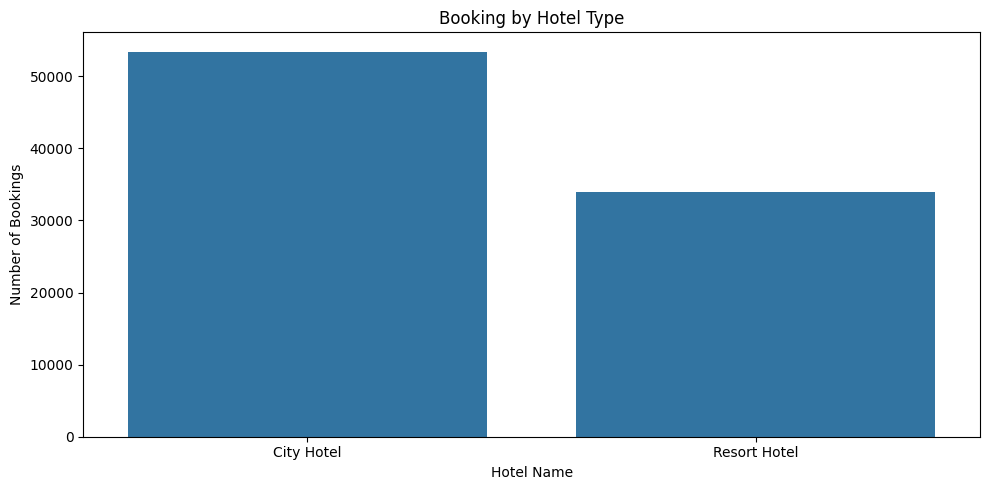

In [19]:
booking_counts = df['hotel'].value_counts()

print(booking_counts)

plt.figure(figsize=(10,5))

sns.barplot(x = booking_counts.index, y = booking_counts.values)

plt.title('Booking by Hotel Type')
plt.xlabel('Hotel Name')
plt.ylabel('Number of Bookings')

plt.tight_layout()
plt.show()

# 3. How many bookings were canceled?

In [20]:
canceled_bookings = df['is_canceled'].sum()

print(f'Total Cancel Bookings :', canceled_bookings)

Total Cancel Bookings : 24024


# 4. What is the most common arrival month for bookings?

In [21]:
arrival_month_counts = df['arrival_date_month'].value_counts()

most_common_month = df['arrival_date_month'].mode()[0]

print("Most Common Arrival Month:", most_common_month)
print("Total Bookings:", arrival_month_counts.max())

Most Common Arrival Month: August
Total Bookings: 11257


# 5. What is the average number of special requests per booking?

In [22]:
avg_no = df['total_of_special_requests'].mean()

print(f'Average no of sp booking: {avg_no:.2f}')

Average no of sp booking: 0.70


# 6. Which country has the highest number of bookings?

In [23]:
Country_counts = df['country'].value_counts()

print('Country With Highest Count:', Country_counts.idxmax())
print('Number of Bookings:', Country_counts.max())

Country With Highest Count: PRT
Number of Bookings: 27886


# 7. What is the average daily rate (ADR) for each hotel type?

In [24]:
df.groupby('hotel')['adr'].mean().round()

hotel
City Hotel      111.0
Resort Hotel     99.0
Name: adr, dtype: float64

# 8. What percentage of guests required car parking spaces?

In [25]:
parking_percentage = (df['required_car_parking_spaces'] > 0).mean() * 100

print(f"Percentage of bookings requiring parking: {parking_percentage:.2f}%")


Percentage of bookings requiring parking: 8.37%


# 9. What is the average stay duration in week nights and weekend nights?


In [26]:
Average_stay = df[['stays_in_week_nights','stays_in_weekend_nights']].mean().round(2)


print(Average_stay)

stays_in_week_nights       2.63
stays_in_weekend_nights    1.01
dtype: float64


# 10. How many bookings were made through travel agents?

In [27]:
agent_bookings = (df['agent'] != 0).sum()

print(f"Bookings made through travel agents:  {agent_bookings}")

Bookings made through travel agents:  75197


# Medium Level
# 1. What is the cancellation rate for each hotel type?

In [28]:
cancellation_rate = df.groupby('hotel')['is_canceled'].mean() * 100

print(cancellation_rate.round(2))

hotel
City Hotel      30.04
Resort Hotel    23.49
Name: is_canceled, dtype: float64


# 2. What is the average ADR per market segment?

In [29]:
Average_ADR = df.groupby('market_segment')['adr'].mean().sort_values(ascending=False)

print(Average_ADR)

market_segment
Online TA        118.173470
Direct           116.595481
Aviation         100.170396
Offline TA/TO     81.773430
Groups            74.821719
Corporate         68.199489
Undefined         15.000000
Complementary      3.049245
Name: adr, dtype: float64


# 3. What is the relationship between lead time and cancellation rate?

Correlation: 0.1847230247911782


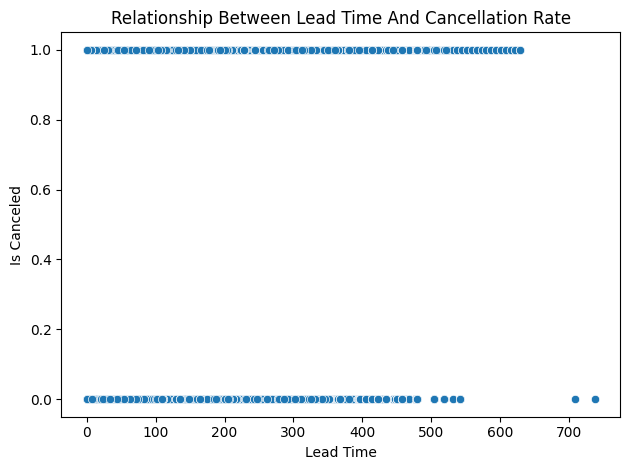

In [30]:
correlation = df['lead_time'].corr(df['is_canceled'])

print("Correlation:", correlation)

sns.scatterplot(data = df, x = 'lead_time', y = 'is_canceled')


plt.title('Relationship Between Lead Time And Cancellation Rate')
plt.xlabel('Lead Time')
plt.ylabel('Is Canceled')

plt.tight_layout()
plt.show()

# 4. Which distribution channel has the highest number of bookings?

In [31]:
Highest_bookings = df.groupby('distribution_channel')['distribution_channel'].count().sort_values(ascending=False)

print(Highest_bookings)

distribution_channel
TA/TO        69136
Direct       12980
Corporate     5075
GDS            181
Undefined        5
Name: distribution_channel, dtype: int64


# 5. What is the average number of previous cancellations by hotel type?

In [32]:
Average_Cancellations = df.groupby('hotel')['previous_cancellations'].mean()


print('Average Previous Cancellations by Hotel:')
print(Average_Cancellations)

Average Previous Cancellations by Hotel:
hotel
City Hotel      0.035768
Resort Hotel    0.022004
Name: previous_cancellations, dtype: float64


# 6. What is the trend of ADR over the years?

arrival_date_year
2015     92.164670
2016    101.542981
2017    118.725867
Name: adr, dtype: float64


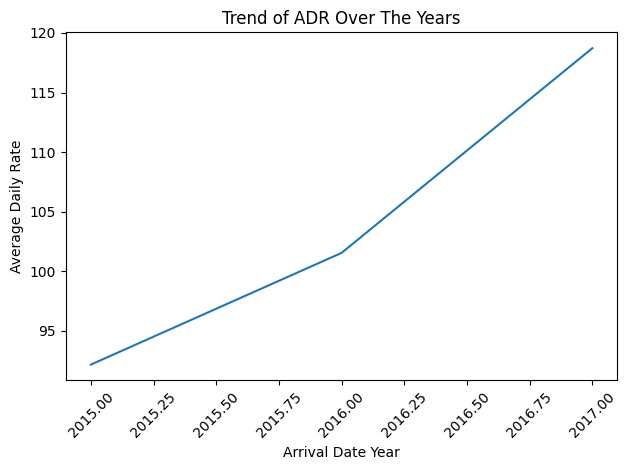

In [33]:
Average_adr = df.groupby(['arrival_date_year'])['adr'].mean()

print(Average_adr)

sns.lineplot( x = Average_adr.index, y = Average_adr.values)

plt.title('Trend of ADR Over The Years')
plt.xlabel('Arrival Date Year')
plt.ylabel('Average Daily Rate')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 7. Which month has the highest revenue?

In [34]:
Highest_revenue = df.groupby('arrival_date_month')['adr'].sum().sort_values(ascending=False)

print('Highest revenue', Highest_revenue )

# August has the highest total ADR value of 1,698,412

Highest revenue arrival_date_month
August       1698412.48
July         1362857.93
June          929859.68
May           929040.10
April         819209.19
September     749823.65
October       625039.56
March         612999.35
February      455226.02
December      417582.11
November      363408.53
January       328658.13
Name: adr, dtype: float64


# 8. What is the impact of special requests on ADR?

In [35]:
correlation = df['total_of_special_requests'].corr(df['adr'])

print(correlation)

0.13765202549293598


# 9. What is the average stay duration for repeated guests versus new guests?

In [36]:
average_stay_duration = df.groupby('is_repeated_guest')[['stays_in_week_nights','stays_in_weekend_nights']].mean()

print("Average Stay Duration:")

print("New Guests (0):")
print(average_stay_duration.loc[0])

print("\nRepeated Guests (1):")
print(average_stay_duration.loc[1])

Average Stay Duration:
New Guests (0):
stays_in_week_nights       2.672685
stays_in_weekend_nights    1.027655
Name: 0, dtype: float64

Repeated Guests (1):
stays_in_week_nights       1.469107
stays_in_weekend_nights    0.457980
Name: 1, dtype: float64


# 10. Which room type has the highest number of bookings?

In [37]:
Highest_Number_of_Bookings = df.groupby('reserved_room_type')['reserved_room_type'].count().sort_values(ascending=False)


print("Most Booked Room:", Highest_Number_of_Bookings.idxmax())
print("Total Bookings:", Highest_Number_of_Bookings.max())


Most Booked Room: A
Total Bookings: 56536


# Advanced Level
# 1. What is the impact of booking changes on guest satisfaction as indicated by special requests?

Correlation: 0.016


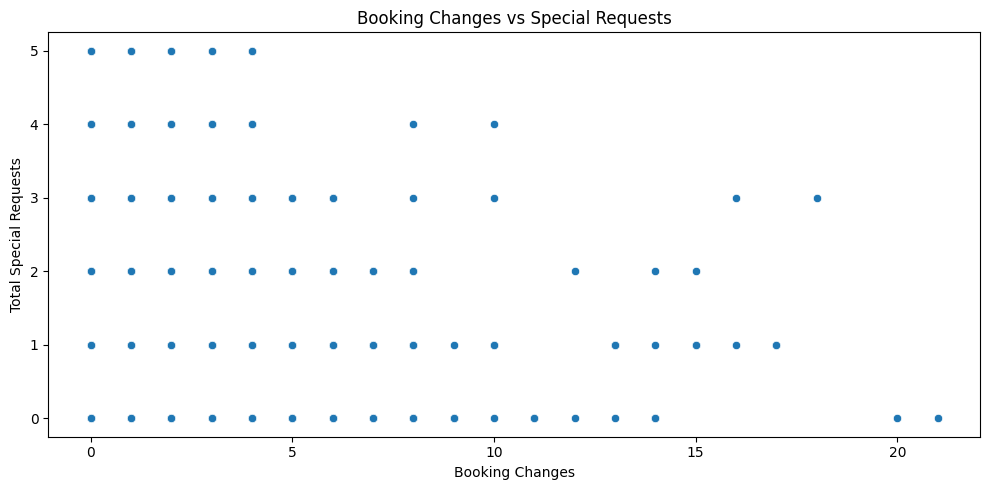

In [38]:
Request_correlation = df['booking_changes'].corr(df['total_of_special_requests'])

print(f"Correlation: {Request_correlation:.3f}")

plt.figure(figsize=(10,5))

sns.scatterplot(data=df,x='booking_changes',y='total_of_special_requests')

plt.title('Booking Changes vs Special Requests')
plt.xlabel('Booking Changes')
plt.ylabel('Total Special Requests')

plt.tight_layout()
plt.show()

# 2. What is the seasonal impact on booking cancellations?

arrival_date_month
August       32.18
July         31.80
April        30.46
June         30.32
May          29.23
December     26.87
September    24.54
March        24.37
October      23.69
February     23.23
January      22.13
November     21.10
Name: is_canceled, dtype: float64


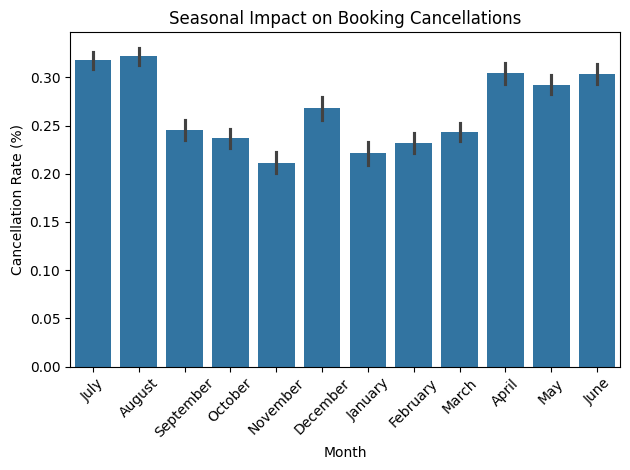

In [39]:
Cancellation_rate = (df.groupby('arrival_date_month')['is_canceled'].mean() * 100).round(2).sort_values(ascending=False)

print(Cancellation_rate)


sns.barplot(data = df, x = 'arrival_date_month', y = 'is_canceled')

plt.title('Seasonal Impact on Booking Cancellations')
plt.xlabel('Month')
plt.ylabel('Cancellation Rate (%)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. How does the booking lead time distribution vary between different market segments?

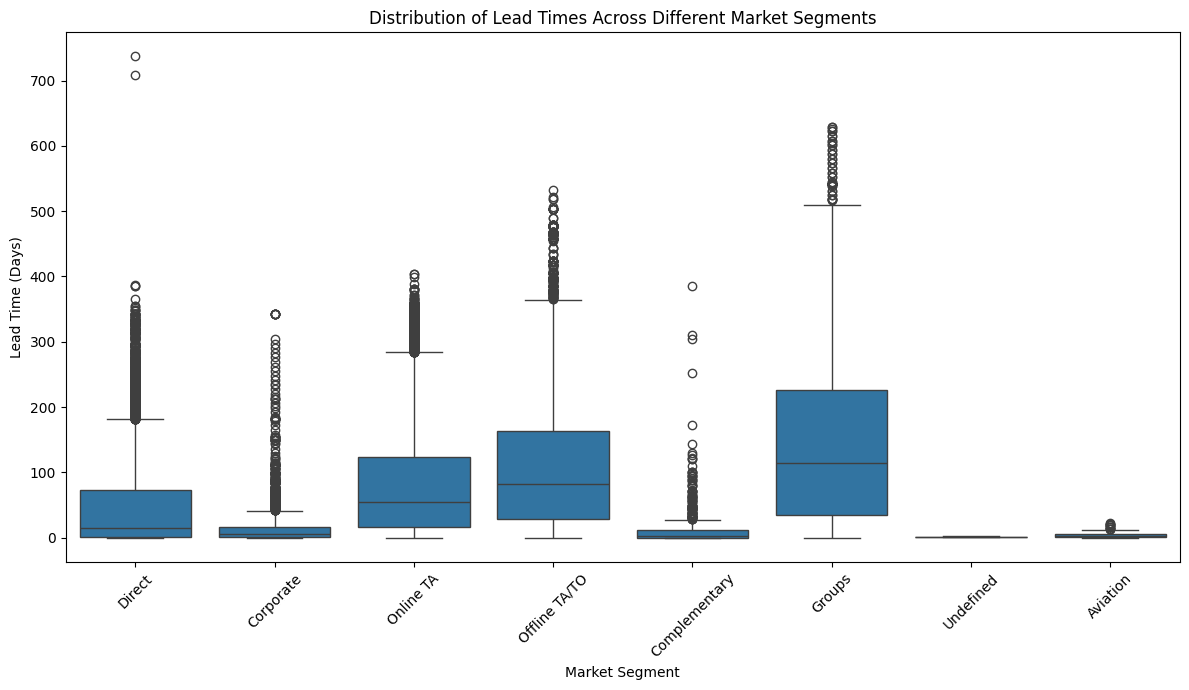

In [40]:
plt.figure(figsize=(12,7))

sns.boxplot(data = df, x = 'market_segment', y = 'lead_time')

plt.title('Distribution of Lead Times Across Different Market Segments')
plt.xlabel('Market Segment')
plt.ylabel('Lead Time (Days)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87377 entries, 0 to 87376
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           87377 non-null  object        
 1   is_canceled                     87377 non-null  int64         
 2   lead_time                       87377 non-null  int64         
 3   arrival_date_year               87377 non-null  int64         
 4   arrival_date_month              87377 non-null  object        
 5   arrival_date_week_number        87377 non-null  int64         
 6   arrival_date_day_of_month       87377 non-null  int64         
 7   stays_in_weekend_nights         87377 non-null  int64         
 8   stays_in_week_nights            87377 non-null  int64         
 9   adults                          87377 non-null  int64         
 10  children                        87377 non-null  float64       
 11  ba